In [2]:
#!pip install torchvision

In [45]:
import torch
import os
from torch.utils.data import DataLoader,Dataset
from torchvision import transforms
from PIL import Image

In [46]:
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # List of paths for all files in the directory
        self.all_img_paths = [os.path.join(root_dir_path, img)for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self,idx):
        img_path=self.all_img_paths[idx]
        img=Image.open(img_path).convert("RGB")

        if self.transformations:
            img=self.transformations(img)

        return img



In [47]:
root_dir_path="./img_align_celeba"

transformations=transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5)) #[-1,1]
])

In [48]:
dataset=ImageProcessor(root_dir_path,transformations)
print(f"loade{len(dataset)} image")

loade202599 image


In [49]:
dataloader=DataLoader(dataset,batch_size=128,shuffle=True)

# Generator Network

In [50]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [85]:
class Generator(nn.Module):
    def __init__(self,z_dim=100,img_channels=3): #3 is for RGB
        super(Generator,self). __init__()

        #fully connected layer
        self.model=nn.Sequential(
            nn.Linear(z_dim,256),
            nn.ReLU(),

            nn.Linear(256,512),
            nn.ReLU(),

            nn.Linear(512,1024),
            nn.ReLU(),

            nn.Linear(1024,64*64*img_channels),
            nn.Tanh()   #[-1,1]
        )

    def forward(self,z):
        img=self.model(z)
        img=img.view(img.size(0),3,64,64)
        return img

# Discriminotor Network

In [86]:
class Discriminator(nn.Module):
    def __init__(self,img_channels=3): #3 is for RGB
        super(Discriminator,self). __init__()

        #fully connected layer
        self.model=nn.Sequential(
            nn.Flatten(),
            
            nn.Linear(img_channels*64*64,1024),
            nn.LeakyReLU(0.2,inplace=True),

            nn.Linear(1024,512),
            nn.LeakyReLU(0.2,inplace=True),

            nn.Linear(512,256),
            nn.LeakyReLU(0.2,inplace=True),

            nn.Linear(256,1),
            nn.Sigmoid()   #[-1,1]
        )

    def forward(self,img):
         return self.model(img)
       

In [87]:
#Loss function

GAN_loss=nn.BCELoss()

generator=Generator()
g_optimizer=optim.Adam(generator.parameters(),lr=0.0002,betas=(0.5,0.999))

discriminator=Discriminator()
d_optimizer=optim.Adam(discriminator.parameters(),lr=0.0002,betas=(0.5,0.999))

In [88]:
import torch

if torch.backends.mps.is_available():
    device=torch.device("mps")
elif torch.cuda.is_available():
    device=torch.device("cuda")
else:
    device=torch.device("cpu")

print(f"device is {device}")

device is cpu


In [89]:
generator=generator.to(device)
discriminator=discriminator.to(device)

In [96]:
# Training the GAN

def train(generator,discriminator,dataloader,epochs=10):

    for epoch in range(epochs):
        for i,imgs in enumerate(dataloader):
            real_imgs=imgs.to(device)
            batch_size=real_imgs.size(0)

            #create real imgs labels & fake img labels
            real_labels=torch.ones(batch_size,1).to(device) #[1,1,1..]
            fake_labels=torch.zeros(batch_size,1).to(device) #[0,0,0,..]

            #train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs=generator(torch.randn(batch_size,100).to(device))

            real_loss=GAN_loss(discriminator(real_imgs),real_labels)
            fake_loss=GAN_loss(discriminator(fake_imgs.detach()),fake_labels)

            d_loss=(real_loss+fake_loss)/2

            d_loss.backward()
            d_optimizer.step()

            #Train the Generator
            g_optimizer.zero_grad()

            g_loss=GAN_loss(discriminator(fake_imgs),real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i%50==0:
                print(f"for optim:{epoch+1}/{epochs}..  batch{i+1}..  G_loss:{g_loss}...  D-losss:{d_loss}")

        #save generated img for each epoch
        save_generated_imges(generator,epoch,device)

In [107]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_imges(generator,epoch,device,num_imgs=8):
    z=torch.randn(num_imgs,100).to(device)
    generated_imgs=generator(z).detach().cpu()

    #[-1,1]==>[0,1]
    grid=torchvision.utils.make_grid(generated_imgs,nrow=4,normalize=True)

    plt.imshow(np.transpose(grid,(1,2,0)))
    plt.title(f"epoch{epoch+1}")
    plt.axis("off")
    plt.show()

for optim:1/2 ..batch1..G_loss3.275264263153076...D-losss:0.2969403862953186
for optim:1/2 ..batch51..G_loss2.0990917682647705...D-losss:0.42929068207740784
for optim:1/2 ..batch101..G_loss2.964564561843872...D-losss:0.35275107622146606
for optim:1/2 ..batch151..G_loss2.000638484954834...D-losss:0.353478342294693
for optim:1/2 ..batch201..G_loss2.3992176055908203...D-losss:0.35586148500442505
for optim:1/2 ..batch251..G_loss2.8623952865600586...D-losss:0.3415878415107727
for optim:1/2 ..batch301..G_loss2.2369043827056885...D-losss:0.2994723916053772
for optim:1/2 ..batch351..G_loss2.8550000190734863...D-losss:0.2961184084415436
for optim:1/2 ..batch401..G_loss1.7647836208343506...D-losss:0.3735082745552063
for optim:1/2 ..batch451..G_loss2.1273529529571533...D-losss:0.40489983558654785
for optim:1/2 ..batch501..G_loss1.893922209739685...D-losss:0.4726099967956543
for optim:1/2 ..batch551..G_loss2.4892213344573975...D-losss:0.4404984712600708
for optim:1/2 ..batch601..G_loss2.1063301563

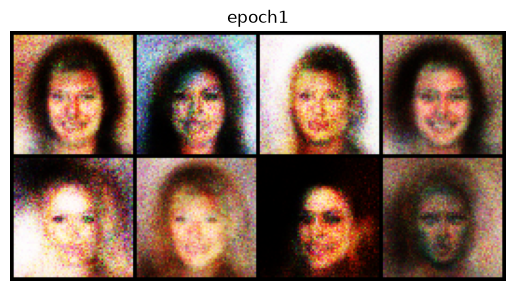

for optim:2/2 ..batch1..G_loss2.0152618885040283...D-losss:0.5072949528694153
for optim:2/2 ..batch51..G_loss2.33502459526062...D-losss:0.40526026487350464
for optim:2/2 ..batch101..G_loss1.8515511751174927...D-losss:0.43358081579208374
for optim:2/2 ..batch151..G_loss1.7284786701202393...D-losss:0.444061279296875
for optim:2/2 ..batch201..G_loss1.5022751092910767...D-losss:0.42846840620040894
for optim:2/2 ..batch251..G_loss2.309098720550537...D-losss:0.43640249967575073
for optim:2/2 ..batch301..G_loss3.0741384029388428...D-losss:0.33919501304626465
for optim:2/2 ..batch351..G_loss1.7698408365249634...D-losss:0.37693697214126587
for optim:2/2 ..batch401..G_loss1.9502952098846436...D-losss:0.407839834690094
for optim:2/2 ..batch451..G_loss1.7648296356201172...D-losss:0.3648275136947632
for optim:2/2 ..batch501..G_loss1.9838731288909912...D-losss:0.4731404781341553
for optim:2/2 ..batch551..G_loss1.5068446397781372...D-losss:0.5528327226638794
for optim:2/2 ..batch601..G_loss2.08382129

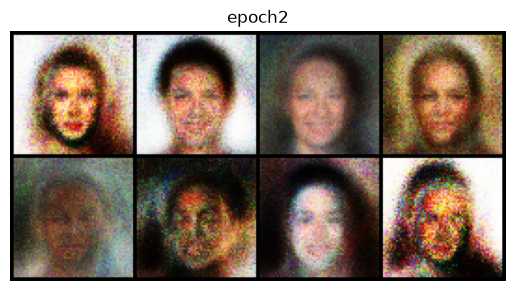

In [108]:
train(generator,discriminator,dataloader,epochs=2)

for optim:1/10 ..batch1..G_loss1.8342903852462769...D-losss:0.5021668672561646
for optim:1/10 ..batch51..G_loss2.071936845779419...D-losss:0.3761913478374481
for optim:1/10 ..batch101..G_loss2.0943925380706787...D-losss:0.3898158669471741
for optim:1/10 ..batch151..G_loss1.8358160257339478...D-losss:0.4290040135383606
for optim:1/10 ..batch201..G_loss2.4839916229248047...D-losss:0.5450980067253113
for optim:1/10 ..batch251..G_loss1.8035414218902588...D-losss:0.49864882230758667
for optim:1/10 ..batch301..G_loss1.715296983718872...D-losss:0.5117595195770264
for optim:1/10 ..batch351..G_loss1.9311496019363403...D-losss:0.4682949483394623
for optim:1/10 ..batch401..G_loss1.68744695186615...D-losss:0.45702728629112244
for optim:1/10 ..batch451..G_loss1.9853243827819824...D-losss:0.4026045501232147
for optim:1/10 ..batch501..G_loss1.794354796409607...D-losss:0.4514182209968567
for optim:1/10 ..batch551..G_loss1.702501893043518...D-losss:0.4197331964969635
for optim:1/10 ..batch601..G_loss2.

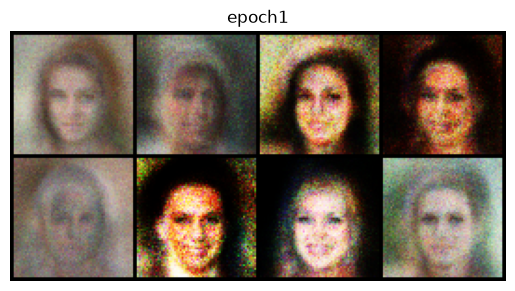

for optim:2/10 ..batch1..G_loss1.407715082168579...D-losss:0.5341538190841675
for optim:2/10 ..batch51..G_loss1.597388505935669...D-losss:0.4714592695236206
for optim:2/10 ..batch101..G_loss1.7941476106643677...D-losss:0.4626089334487915
for optim:2/10 ..batch151..G_loss1.7926242351531982...D-losss:0.46129047870635986
for optim:2/10 ..batch201..G_loss1.7215818166732788...D-losss:0.48981958627700806
for optim:2/10 ..batch251..G_loss1.5405659675598145...D-losss:0.5818522572517395
for optim:2/10 ..batch301..G_loss1.7682431936264038...D-losss:0.4575658440589905
for optim:2/10 ..batch351..G_loss2.2753899097442627...D-losss:0.4897516071796417
for optim:2/10 ..batch401..G_loss1.7226192951202393...D-losss:0.43854865431785583
for optim:2/10 ..batch451..G_loss1.8639426231384277...D-losss:0.4878849983215332
for optim:2/10 ..batch501..G_loss1.6108962297439575...D-losss:0.5148823261260986
for optim:2/10 ..batch551..G_loss1.8588656187057495...D-losss:0.4812264144420624
for optim:2/10 ..batch601..G_l

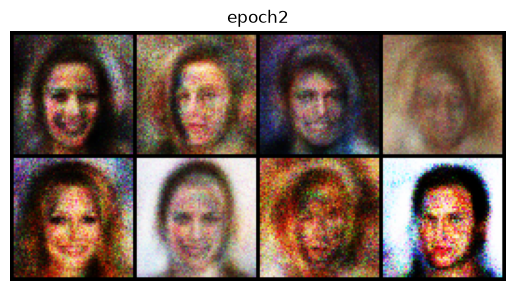

for optim:3/10 ..batch1..G_loss1.5669164657592773...D-losss:0.5193899869918823
for optim:3/10 ..batch51..G_loss1.8029853105545044...D-losss:0.4982631206512451
for optim:3/10 ..batch101..G_loss1.9286775588989258...D-losss:0.5505436658859253
for optim:3/10 ..batch151..G_loss1.3349329233169556...D-losss:0.6169148087501526
for optim:3/10 ..batch201..G_loss1.5576000213623047...D-losss:0.5007820725440979
for optim:3/10 ..batch251..G_loss1.4772756099700928...D-losss:0.561627984046936
for optim:3/10 ..batch301..G_loss1.5274691581726074...D-losss:0.5150901079177856
for optim:3/10 ..batch351..G_loss1.4563885927200317...D-losss:0.5353452563285828
for optim:3/10 ..batch401..G_loss1.723960041999817...D-losss:0.48264068365097046
for optim:3/10 ..batch451..G_loss1.3964868783950806...D-losss:0.49259406328201294
for optim:3/10 ..batch501..G_loss1.6615703105926514...D-losss:0.47841814160346985
for optim:3/10 ..batch551..G_loss1.6980448961257935...D-losss:0.5143452882766724
for optim:3/10 ..batch601..G_l

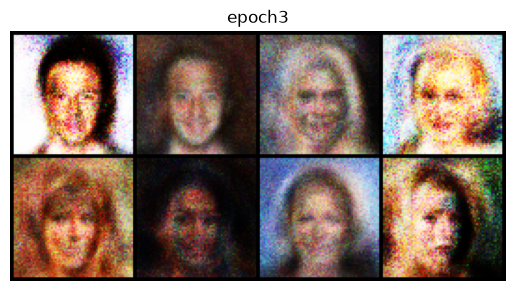

for optim:4/10 ..batch1..G_loss1.565606713294983...D-losss:0.5627331733703613
for optim:4/10 ..batch51..G_loss1.5463789701461792...D-losss:0.5152034759521484
for optim:4/10 ..batch101..G_loss1.6550250053405762...D-losss:0.5596993565559387
for optim:4/10 ..batch151..G_loss1.536628007888794...D-losss:0.5261272192001343
for optim:4/10 ..batch201..G_loss1.483534574508667...D-losss:0.593408465385437
for optim:4/10 ..batch251..G_loss1.9210532903671265...D-losss:0.5039432048797607
for optim:4/10 ..batch301..G_loss1.5091543197631836...D-losss:0.5783905982971191
for optim:4/10 ..batch351..G_loss1.8302562236785889...D-losss:0.5344993472099304
for optim:4/10 ..batch401..G_loss1.5584847927093506...D-losss:0.501885712146759
for optim:4/10 ..batch451..G_loss1.4218026399612427...D-losss:0.5870273113250732
for optim:4/10 ..batch501..G_loss1.6360127925872803...D-losss:0.48963662981987
for optim:4/10 ..batch551..G_loss1.4087682962417603...D-losss:0.5766041874885559
for optim:4/10 ..batch601..G_loss1.463

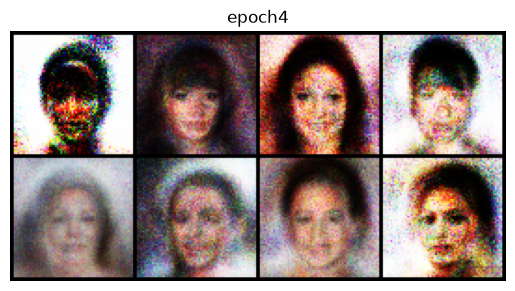

for optim:5/10 ..batch1..G_loss1.495728850364685...D-losss:0.5204333662986755
for optim:5/10 ..batch51..G_loss1.577376127243042...D-losss:0.547807514667511
for optim:5/10 ..batch101..G_loss1.4074554443359375...D-losss:0.4819644093513489
for optim:5/10 ..batch151..G_loss1.639084815979004...D-losss:0.5202898979187012
for optim:5/10 ..batch201..G_loss1.5473318099975586...D-losss:0.5979169607162476
for optim:5/10 ..batch251..G_loss1.5273411273956299...D-losss:0.5458276271820068
for optim:5/10 ..batch301..G_loss1.3893675804138184...D-losss:0.5250886082649231
for optim:5/10 ..batch351..G_loss1.443436861038208...D-losss:0.5705921053886414
for optim:5/10 ..batch401..G_loss1.4070918560028076...D-losss:0.5808026194572449
for optim:5/10 ..batch451..G_loss1.4639062881469727...D-losss:0.5679246783256531
for optim:5/10 ..batch501..G_loss1.3381116390228271...D-losss:0.5434653162956238
for optim:5/10 ..batch551..G_loss1.3817079067230225...D-losss:0.5428181886672974
for optim:5/10 ..batch601..G_loss1.3

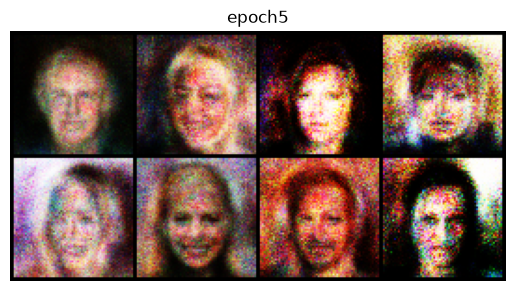

for optim:6/10 ..batch1..G_loss1.4233815670013428...D-losss:0.5783286690711975
for optim:6/10 ..batch51..G_loss1.4138994216918945...D-losss:0.5531041622161865
for optim:6/10 ..batch101..G_loss1.4857368469238281...D-losss:0.5061219930648804
for optim:6/10 ..batch151..G_loss1.410253643989563...D-losss:0.642808198928833
for optim:6/10 ..batch201..G_loss1.3831875324249268...D-losss:0.5512222051620483
for optim:6/10 ..batch251..G_loss1.4242520332336426...D-losss:0.5336704254150391
for optim:6/10 ..batch301..G_loss1.539237141609192...D-losss:0.6180704832077026
for optim:6/10 ..batch351..G_loss1.4711641073226929...D-losss:0.5459017157554626
for optim:6/10 ..batch401..G_loss1.2676717042922974...D-losss:0.5505750179290771
for optim:6/10 ..batch451..G_loss1.4663779735565186...D-losss:0.535210132598877
for optim:6/10 ..batch501..G_loss1.4284558296203613...D-losss:0.511682391166687
for optim:6/10 ..batch551..G_loss1.4302256107330322...D-losss:0.5178102850914001
for optim:6/10 ..batch601..G_loss1.4

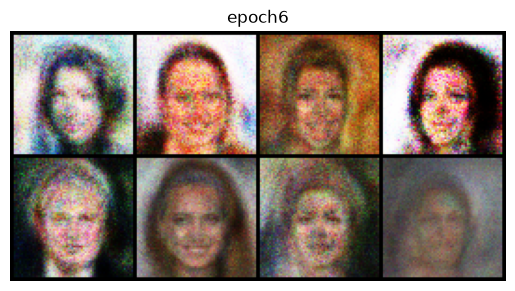

for optim:7/10 ..batch1..G_loss1.3646349906921387...D-losss:0.5383723974227905
for optim:7/10 ..batch51..G_loss1.3675737380981445...D-losss:0.5885109901428223
for optim:7/10 ..batch101..G_loss1.393401861190796...D-losss:0.5314900279045105
for optim:7/10 ..batch151..G_loss1.1909466981887817...D-losss:0.5848095417022705
for optim:7/10 ..batch201..G_loss1.4466221332550049...D-losss:0.5291621685028076
for optim:7/10 ..batch251..G_loss1.306852102279663...D-losss:0.5530397891998291
for optim:7/10 ..batch301..G_loss1.5623831748962402...D-losss:0.5486971139907837
for optim:7/10 ..batch351..G_loss1.3699923753738403...D-losss:0.6029602289199829
for optim:7/10 ..batch401..G_loss1.3510496616363525...D-losss:0.5682365298271179
for optim:7/10 ..batch451..G_loss1.3211411237716675...D-losss:0.5065947771072388
for optim:7/10 ..batch501..G_loss1.379894495010376...D-losss:0.5536757707595825
for optim:7/10 ..batch551..G_loss1.3879787921905518...D-losss:0.6509830355644226
for optim:7/10 ..batch601..G_loss1

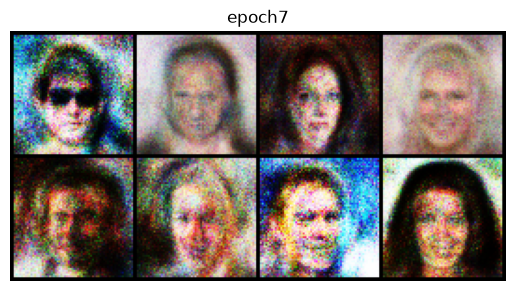

for optim:8/10 ..batch1..G_loss1.3943731784820557...D-losss:0.5800831317901611
for optim:8/10 ..batch51..G_loss1.3564772605895996...D-losss:0.5557692050933838
for optim:8/10 ..batch101..G_loss1.4800865650177002...D-losss:0.5346382856369019
for optim:8/10 ..batch151..G_loss1.397956132888794...D-losss:0.5573538541793823
for optim:8/10 ..batch201..G_loss1.365224838256836...D-losss:0.5349098443984985
for optim:8/10 ..batch251..G_loss1.2504501342773438...D-losss:0.5690821409225464
for optim:8/10 ..batch301..G_loss1.1932016611099243...D-losss:0.6263790130615234
for optim:8/10 ..batch351..G_loss1.1795207262039185...D-losss:0.5840767025947571
for optim:8/10 ..batch401..G_loss1.3151254653930664...D-losss:0.5644860863685608
for optim:8/10 ..batch451..G_loss1.146018385887146...D-losss:0.638607382774353
for optim:8/10 ..batch501..G_loss1.2093451023101807...D-losss:0.579339861869812
for optim:8/10 ..batch551..G_loss1.2885197401046753...D-losss:0.5865353345870972
for optim:8/10 ..batch601..G_loss1.3

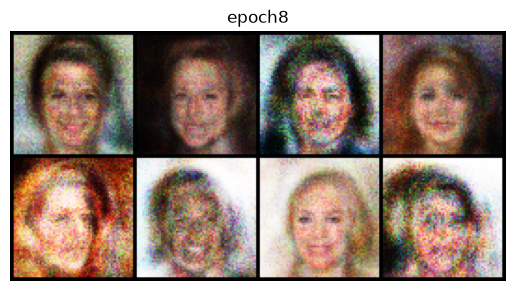

for optim:9/10 ..batch1..G_loss1.3143219947814941...D-losss:0.5931150317192078
for optim:9/10 ..batch51..G_loss1.3763556480407715...D-losss:0.5833393335342407
for optim:9/10 ..batch101..G_loss1.2345396280288696...D-losss:0.5465883016586304
for optim:9/10 ..batch151..G_loss1.3820151090621948...D-losss:0.6107107400894165
for optim:9/10 ..batch201..G_loss1.3901317119598389...D-losss:0.5348130464553833
for optim:9/10 ..batch251..G_loss1.3105888366699219...D-losss:0.6387441754341125
for optim:9/10 ..batch301..G_loss1.3684806823730469...D-losss:0.5539657473564148
for optim:9/10 ..batch351..G_loss1.3143624067306519...D-losss:0.6208329200744629
for optim:9/10 ..batch401..G_loss1.4027780294418335...D-losss:0.5822316408157349
for optim:9/10 ..batch451..G_loss1.3176997900009155...D-losss:0.5769591927528381
for optim:9/10 ..batch501..G_loss1.391231894493103...D-losss:0.5471682548522949
for optim:9/10 ..batch551..G_loss1.2812997102737427...D-losss:0.5834918022155762
for optim:9/10 ..batch601..G_los

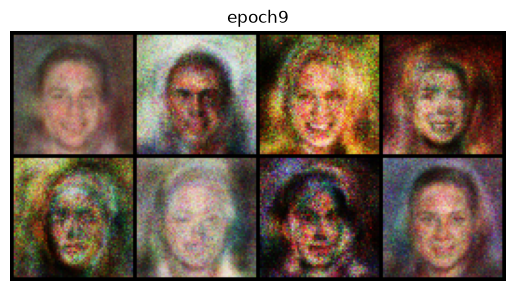

for optim:10/10 ..batch1..G_loss1.1855982542037964...D-losss:0.6136656999588013
for optim:10/10 ..batch51..G_loss1.272714614868164...D-losss:0.5520949363708496
for optim:10/10 ..batch101..G_loss1.3285231590270996...D-losss:0.5592284202575684
for optim:10/10 ..batch151..G_loss1.4042866230010986...D-losss:0.5857175588607788
for optim:10/10 ..batch201..G_loss1.3089274168014526...D-losss:0.5502302646636963
for optim:10/10 ..batch251..G_loss1.197033405303955...D-losss:0.5883128643035889
for optim:10/10 ..batch301..G_loss1.3150824308395386...D-losss:0.5748805999755859
for optim:10/10 ..batch351..G_loss1.3264354467391968...D-losss:0.5777164697647095
for optim:10/10 ..batch401..G_loss1.5047669410705566...D-losss:0.5775154232978821
for optim:10/10 ..batch451..G_loss1.3773927688598633...D-losss:0.48293164372444153
for optim:10/10 ..batch501..G_loss1.3353763818740845...D-losss:0.558759331703186
for optim:10/10 ..batch551..G_loss1.237501621246338...D-losss:0.5894796848297119
for optim:10/10 ..batc

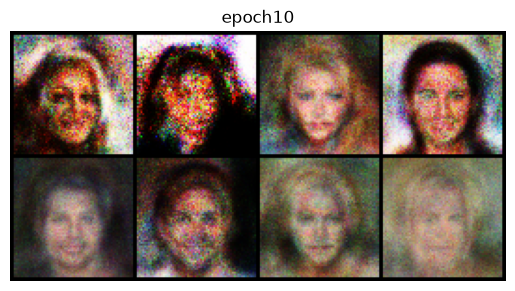

In [109]:
train(generator,discriminator,dataloader,epochs=10)